In [1]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
import operator as op
warnings.filterwarnings('ignore')

df = pd.read_csv('output_08-10-2026_09-03-11.csv',
                 parse_dates=["start_time", "end_time"],
                 date_format="%m-%d-%Y %H:%M:%S")

df = df.loc[df['inc'] != 4]

# if you need another csv then:
df_temp = pd.read_csv('output_16-10-2026_12-44-43.csv',
                      parse_dates=["start_time", "end_time"],
                 date_format="%m-%d-%Y %H:%M:%S")
df = pd.concat([df, df_temp], ignore_index=True)

df['exp_parameters'] = df['exp_parameters'].astype(str).str.strip()

word_count = df['exp_parameters'].str.split().str.len()

df.loc[word_count == 1, 'exp_parameters'] = df['exp_parameters'] + ' default'

print(f'Shape: {df.shape}')
print(df['exp_parameters'].unique())



Shape: (5100, 52)
['VDSL mps' 'VDSL default' 'VDSL mnp' 'VDSL ptc' 'VDSL sdt' 'VDSL inc'
 'Fiber mps' 'Fiber default' 'Fiber mnp' 'Fiber ptc' 'Fiber sdt'
 'Fiber inc' 'Cable mps' 'Cable default' 'Cable mnp' 'Cable ptc'
 'Cable sdt' 'Cable inc']


In [2]:

rpm_cols = [c for c in df.columns if 'rpm' in c.lower()]

fieldnames = ['exp_parameters']
environment_parameters = ['dl_capacity', 'ul_capacity', 'dl_delay', 'ul_delay']

rpm_parameters = ['id', 'inc', 'inp', 'mad', 'mnp', 'mps', 'p', 'ptc', 'sdt', 'timeout', 'tmp']

dl_test_output = ['dl_stable_throughput', 'dl_stable_responsiveness', 'dl_throughput', 'dl_connections',
                   'dl_max_path_mtu', 'dl_max_send_mss', 'dl_max_recv_mss', 'dl_retransmissions',
                   'dl_reorder', 'dl_avg_rtt', 'dl_rpm_p', 'dl_rpm_trimmed']

ul_test_output = ['ul_stable_throughput', 'ul_stable_responsiveness', 'ul_throughput', 'ul_connections',
                   'ul_max_path_mtu', 'ul_max_send_mss', 'ul_max_recv_mss', 'ul_retransmissions',
                   'ul_reorder', 'ul_avg_rtt', 'ul_rpm_p', 'ul_rpm_trimmed']

final_test_output = ['final_rpm_p', 'final_rpm_trimmed']

relative_test_output = ['ub_base_rpm_p', 'ub_base_rpm_trimmed', 'base_rpm_p', 'base_rpm_trimmed',
                         'wc_effect_p', 'wc_effect_trimmed']
misc = ['iteration', 'start_time', 'end_time']

outputs = dl_test_output + ul_test_output + final_test_output + relative_test_output

not_relevant = ["mtu", "mss"]

outputs_for_plots = [
    item for item in outputs 
    if not any(sub in item for sub in not_relevant)
]


bool_cols = ['dl_stable_throughput', 'dl_stable_responsiveness',
             'ul_stable_throughput', 'ul_stable_responsiveness']

relevant_parameters = ['intervalDuration', 'connectionsPerInterval', 'connectionsInitial', 'movingAverageDistance', 'maxParallelConnections', 
                       'probesPerSecond', 'percentageOfResults', 'capacityOfProbes', 'stabilityCutoff', 'calculationTime']
for c in bool_cols:
    if c in df.columns and df[c].dtype == object:
        df[c] = df[c].map({'True': True, 'False': False})

environments = ['VDSL', 'Cable', 'Fiber']

# rename the parameters to something readable:
rename_map = {
    'id': 'intervalDuration',
    'inc': 'connectionsPerInterval', 
    'inp': 'connectionsInitial', 
    'mad': 'movingAverageDistance', 
    'mnp': 'maxParallelConnections', 
    'mps': 'probesPerSecond', 
    'p': 'percentageOfResults', 
    'ptc': 'capacityOfProbes', 
    'sdt': 'stabilityCutoff', 
    'timeout': 'calculationTime',
    'tmp': 'trimPercentage'
}

default_values = {
    'intervalDuration': 5,
    'connectionsPerInterval': 1,
    'connectionsInitial': 1,
    'movingAverageDistance': 4,
    'maxParallelConnections': 16,
    'probesPerSecond': 100,
    'percentageOfResults': 90,
    'capacityOfProbes': 0.05,
    'stabilityCutoff': 5,
    'calculationTime': 20,
    'trimPercentage': 5
}

df = df.rename(columns=rename_map)
for old_name, new_name in rename_map.items():
    # '\b' ensures we match the exact word, not parts of other words
    regex_pattern = rf'\b{old_name}\b'
    
    df['exp_parameters'] = df['exp_parameters'].str.replace(regex_pattern, new_name, regex=True)

parameter_ranges = {}

for param in relevant_parameters:
    parameter_ranges[param] = df[param].unique()

df.head()

,exp_parameters,dl_capacity,ul_capacity,dl_delay,ul_delay,intervalDuration,connectionsPerInterval,connectionsInitial,movingAverageDistance,maxParallelConnections,...,ub_base_rpm_p,ub_base_rpm_trimmed,base_rpm_p,base_rpm_trimmed,wc_effect_p,wc_effect_trimmed,iteration,start_time,end_time,result_time
0,VDSL probesPerSecond,100,40,5,5,1,1,1,4,16,...,5419,5479,5417,5474,3,8,79,2026-10-08 14:53:04,NaT,10-08-2026 14:54:42
1,VDSL probesPerSecond,100,40,5,5,1,1,1,4,16,...,5415,5468,5418,5470,3,8,50,2026-10-08 14:04:05,NaT,10-08-2026 14:05:43
2,VDSL probesPerSecond,100,40,5,5,1,1,1,4,16,...,5424,5482,5427,5486,4,9,23,2026-10-08 13:18:30,NaT,10-08-2026 13:20:08
3,VDSL probesPerSecond,100,40,5,5,1,1,1,4,16,...,5417,5475,5423,5481,4,9,68,2026-10-08 14:34:30,NaT,10-08-2026 14:36:08
4,VDSL probesPerSecond,100,40,5,5,1,1,1,4,16,...,5409,5462,5406,5462,5,9,92,2026-10-08 15:15:02,NaT,10-08-2026 15:16:40


In [3]:
# cleanup the dataset
is_nan = df[rpm_cols].isna()
is_inf = df[rpm_cols].isin([np.inf, -np.inf])
invalid_rpm = is_nan | is_inf

df_clean = df[~invalid_rpm.any(axis=1)].copy()

df_clean = df_clean.reset_index(drop=True)

# Standard deviation of each experiment

In [4]:
rpm_trimmed_cols = [c for c in df_clean.columns if 'rpm_trimmed' in c.lower()]

if not rpm_trimmed_cols:
    raise ValueError("No columns containing 'rpm_trimmed' were found.")

df_numeric = df_clean[rpm_trimmed_cols].apply(pd.to_numeric, errors='coerce')

stats = (
    df_numeric.apply(
        lambda s: pd.Series({
            'mean': s.mean(),
            'median': s.median(),
            'std': s.std(),
            'variance': s.var(),
            'min': s.min(),
            'max': s.max(),
            'count': s.count(),
            'p25': s.quantile(0.25),
            'p75': s.quantile(0.75),
            'iqr': s.quantile(0.75) - s.quantile(0.25)
        })
    )
    .T
    .round(4)
)

stats

,mean,median,std,variance,min,max,count,p25,p75,iqr
dl_rpm_trimmed,861.3541,782.5,274.5127,7.535722e+04,340.0,1654.0,5100.0,708.0,1104.25,396.25
ul_rpm_trimmed,466.0618,111.0,522.7609,2.732789e+05,31.0,1660.0,5100.0,68.0,977.25,909.25
final_rpm_trimmed,530.1806,220.0,456.9167,2.087729e+05,107.0,1501.0,5100.0,173.0,1035.00,862.00
ub_base_rpm_trimmed,5014.4451,5473.0,1606.3557,2.580379e+06,2834.0,6751.0,5100.0,2861.0,6708.00,3847.00
base_rpm_trimmed,5014.2739,5473.0,1606.3937,2.580501e+06,2846.0,6749.0,5100.0,2861.0,6708.00,3847.00


## for each unique experiment

In [5]:
for exp in df_clean['exp_parameters'].dropna().unique():
    df_exp = df_clean.loc[df_clean['exp_parameters'] == exp]
    df_numeric = df_exp[rpm_trimmed_cols].apply(pd.to_numeric, errors='coerce')

    stats = (
        df_numeric.apply(
            lambda s: pd.Series({
                'mean': s.mean(),
                'median': s.median(),
                'std': s.std(),
                'variance': s.var(),
                'min': s.min(),
                'max': s.max(),
                'count': s.count(),
                'p25': s.quantile(0.25),
                'p75': s.quantile(0.75),
                'iqr': s.quantile(0.75) - s.quantile(0.25)
            })
        )
        .T
        .round(4)
    )

    print(f"\n=== exp_parameters: {exp} ===")
    print(stats.to_string())


=== exp_parameters: VDSL probesPerSecond ===
                         mean  median       std    variance     min     max  count      p25     p75     iqr
dl_rpm_trimmed        748.306   744.0   34.6458   1200.3330   658.0   879.0  500.0   729.75   760.0   30.25
ul_rpm_trimmed        215.006   136.5  183.3072  33601.5130    33.0   537.0  500.0    46.00   381.0  335.00
final_rpm_trimmed     330.740   279.5  189.9871  36095.0946   107.0   636.0  500.0   139.75   518.0  378.25
ub_base_rpm_trimmed  5464.430  5483.0   61.2613   3752.9510  5220.0  5504.0  500.0  5471.00  5490.0   19.00
base_rpm_trimmed     5464.822  5483.0   61.1778   3742.7198  5222.0  5506.0  500.0  5471.00  5489.0   18.00

=== exp_parameters: VDSL default ===
                        mean  median      std  variance     min     max  count      p25      p75    iqr
dl_rpm_trimmed        734.60   733.0  25.6137  656.0606   684.0   828.0  100.0   722.00   745.00  23.00
ul_rpm_trimmed         71.01    71.0   8.0183   64.2928    5

## heatmap of the stds

In [6]:
rpm_trimmed_cols = [c for c in df_clean.columns if 'rpm_trimmed' in c.lower()]
if not rpm_trimmed_cols:
    raise ValueError("No columns containing 'rpm_trimmed' were found.")

df_numeric = df_clean[rpm_trimmed_cols].apply(pd.to_numeric, errors='coerce')
exp_names = df_clean['exp_parameters'].dropna().unique()

# 1) std summary table
std_table = []
for exp in exp_names:
    row = (
        df_numeric.loc[df_clean['exp_parameters'] == exp]
        .std(ddof=1, skipna=True)
    )
    std_table.append(row)

std_df = pd.concat(std_table, axis=1).T
std_df.index = exp_names
std_df = std_df.round(4)

print("Standard deviation per experiment and rpm_trimmed column:")
display(std_df)

Standard deviation per experiment and rpm_trimmed column:


,dl_rpm_trimmed,ul_rpm_trimmed,final_rpm_trimmed,ub_base_rpm_trimmed,base_rpm_trimmed
VDSL probesPerSecond,34.6458,183.3072,189.9871,61.2613,61.1778
VDSL default,25.6137,8.0183,15.2828,5.1189,4.9162
VDSL maxParallelConnections,31.2382,8.0819,14.9723,5.2661,5.4283
VDSL capacityOfProbes,33.8926,8.5403,15.3771,5.3278,5.7998
VDSL stabilityCutoff,36.1470,8.3273,16.0478,12.8369,16.2132
VDSL connectionsPerInterval,49.8114,11.5055,17.3402,5.2879,5.5888
Fiber probesPerSecond,113.2493,175.2235,107.9423,21.6958,21.9779
Fiber default,109.7232,108.1203,78.6640,9.3030,9.4270
Fiber maxParallelConnections,119.7123,91.0549,79.8763,9.0397,9.9477
Fiber capacityOfProbes,101.0237,115.9044,77.6855,9.5913,9.7835


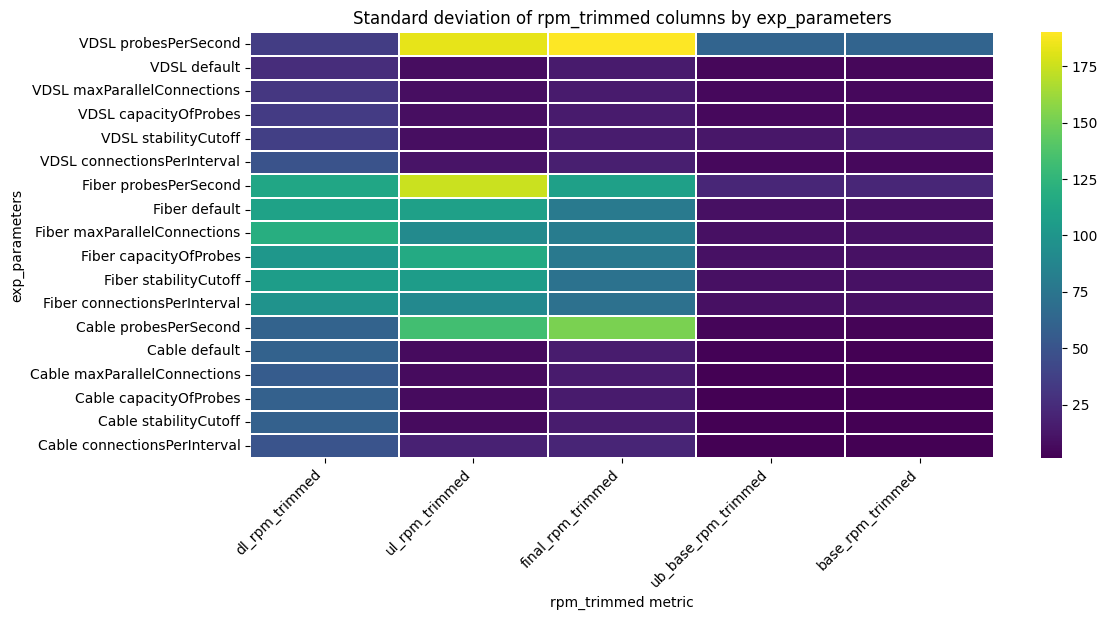

In [11]:
rpm_trimmed_cols = [c for c in df_clean.columns if 'rpm_trimmed' in c.lower()]
df_numeric = df_clean[rpm_trimmed_cols].apply(pd.to_numeric, errors='coerce')

std_table = []
for exp in df_clean['exp_parameters'].dropna().unique():
    row = df_numeric.loc[df_clean['exp_parameters'] == exp].std(ddof=1, skipna=True)
    std_table.append(row)

std_df = pd.concat(std_table, axis=1).T
std_df.index = df_clean['exp_parameters'].dropna().unique()
std_df = std_df.round(4)

plt.figure(figsize=(12, max(5, len(std_df) * 0.35)))
sns.heatmap(std_df, cmap="viridis", annot=False, linewidths=0.1)
plt.title("Standard deviation of rpm_trimmed columns by exp_parameters")
plt.xlabel("rpm_trimmed metric")
plt.ylabel("exp_parameters")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()